<a href="https://colab.research.google.com/github/njalagam23/neural-networks-from-scratch/blob/main/day04_custom_nn_module_churn_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

rng = np.random.default_rng(42)

# Generate 400 synthetic customers
n = 400

usage = rng.uniform(0, 40, n)
tenure = rng.integers(1, 61, n)
tickets = rng.poisson(1.5, n)

X = np.column_stack([usage, tenure, tickets])

# Simulated churn outcomes
logits = 0.9 - 0.14 * usage - 0.035 * tenure + 0.9 * tickets
true_probs = 1 / (1 + np.exp(-logits))

y = (rng.random(n) < true_probs).astype(float).reshape(-1, 1)

# Train/test split
idx = rng.permutation(n)
train_idx, test_idx = idx[:320], idx[320:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Standardize using training statistics only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (320, 3)
Testing: (80, 3)


In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

torch.manual_seed(42)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print(X_train_t.shape)
print(y_train_t.shape)

torch.Size([320, 3])
torch.Size([320, 1])


In [3]:
class ChurnModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.hidden = nn.Linear(3, 8)
        self.output = nn.Linear(8, 1)

    def forward(self, x):

        x = self.hidden(x)
        x = torch.relu(x)

        x = self.output(x)

        return x


model = ChurnModel()

print(model)

ChurnModel(
  (hidden): Linear(in_features=3, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
)


In [4]:
def train_model(model, X, y, epochs=600, lr=0.2):

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr
    )

    history = []

    model.train()

    for epoch in range(epochs):

        logits = model(X)

        loss = criterion(logits, y)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        history.append(loss.item())

        if (epoch + 1) % 100 == 0:
            print(
                f"Epoch {epoch+1}: "
                f"Loss = {loss.item():.4f}"
            )

    return history

In [5]:
loss_history = train_model(
    model,
    X_train_t,
    y_train_t
)

Epoch 100: Loss = 0.3695
Epoch 200: Loss = 0.3398
Epoch 300: Loss = 0.3336
Epoch 400: Loss = 0.3298
Epoch 500: Loss = 0.3269
Epoch 600: Loss = 0.3251


In [6]:
model.eval()

with torch.no_grad():

    test_logits = model(X_test_t)

    probabilities = torch.sigmoid(test_logits)

    predictions = (
        probabilities >= 0.5
    ).int().numpy().flatten()

actual = y_test_t.int().numpy().flatten()

accuracy = accuracy_score(actual, predictions)
precision = precision_score(actual, predictions, zero_division=0)
recall = recall_score(actual, predictions, zero_division=0)
f1 = f1_score(actual, predictions, zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(actual, predictions))

print("\nClassification Report:")
print(classification_report(actual, predictions, zero_division=0))

Accuracy: 0.8375
Precision: 0.9412
Recall: 0.5714
F1 Score: 0.7111

Confusion Matrix:
[[51  1]
 [12 16]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.98      0.89        52
           1       0.94      0.57      0.71        28

    accuracy                           0.84        80
   macro avg       0.88      0.78      0.80        80
weighted avg       0.86      0.84      0.83        80



In [7]:
new_customer = np.array([[8, 5, 4]])

# Use mean and std from Day 3 preprocessing
new_customer_scaled = (new_customer - mean) / std

new_customer_t = torch.tensor(
    new_customer_scaled,
    dtype=torch.float32
)

model.eval()

with torch.no_grad():

    logit = model(new_customer_t)

    churn_probability = torch.sigmoid(logit).item()

print(
    f"Churn probability: "
    f"{churn_probability:.2%}"
)

Churn probability: 88.57%


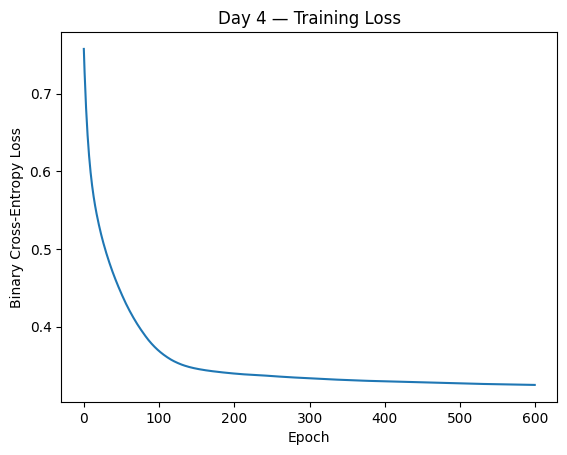

In [8]:
plt.plot(loss_history)

plt.title("Day 4 — Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

plt.show()

In [9]:
assert X_train_t.shape == (320, 3)
assert y_train_t.shape == (320, 1)

assert len(loss_history) == 600
assert np.isfinite(loss_history).all()

assert loss_history[-1] < loss_history[0]

assert 0 <= accuracy <= 1
assert 0 <= precision <= 1
assert 0 <= recall <= 1
assert 0 <= f1 <= 1

print("All basic checks passed!")

All basic checks passed!
